<a href="https://colab.research.google.com/github/swethaeng2007-creator/ML-23CSE301/blob/main/Experiment-02-Logistic-Regression/Logistic_Regression_Exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
df = pd.read_stata("binary.dta")

df.head()

,admit,gre,gpa,rank
0,0.0,380.0,3.61,3.0
1,1.0,660.0,3.67,3.0
2,1.0,800.0,4.00,1.0
3,1.0,640.0,3.19,4.0
4,0.0,520.0,2.93,4.0


In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nInformation:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

Shape: (400, 4)

Columns:
Index(['admit', 'gre', 'gpa', 'rank'], dtype='object')

Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   admit   400 non-null    float32
 1   gre     400 non-null    float32
 2   gpa     400 non-null    float32
 3   rank    400 non-null    float32
dtypes: float32(4)
memory usage: 6.4 KB
None

Missing Values:
admit    0
gre      0
gpa      0
rank     0
dtype: int64

Statistical Summary:
            admit         gre         gpa        rank
count  400.000000  400.000000  400.000000  400.000000
mean     0.317500  587.700012    3.389900    2.485000
std      0.466087  115.516663    0.380567    0.944462
min      0.000000  220.000000    2.260000    1.000000
25%      0.000000  520.000000    3.130000    2.000000
50%      0.000000  580.000000    3.395000    2.000000
75%      1.000000  660.000000    3.670000    3.000000
max   

In [4]:
X = df[['gre', 'gpa', 'rank']]
y = df['admit']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [6]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [7]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred)

Predictions:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 1. 0. 0.]


In [8]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.6625

Confusion Matrix:
[[51  2]
 [25  2]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.67      0.96      0.79        53
         1.0       0.50      0.07      0.13        27

    accuracy                           0.66        80
   macro avg       0.59      0.52      0.46        80
weighted avg       0.61      0.66      0.57        80



In [9]:
new_student = pd.DataFrame({
    'gre': [650],
    'gpa': [3.5],
    'rank': [2]
})

prediction = model.predict(new_student)

if prediction[0] == 1:
    print("Prediction: Admitted")
else:
    print("Prediction: Not Admitted")

Prediction: Not Admitted


  Feature  Coefficient
0     gre     0.001853
1     gpa     0.782977
2    rank    -0.602242


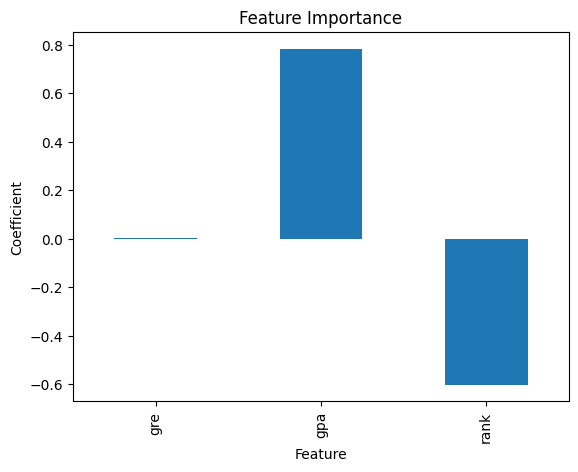

In [10]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

print(importance)

importance.plot(
    x='Feature',
    y='Coefficient',
    kind='bar',
    legend=False,
    title='Feature Importance'
)

plt.ylabel("Coefficient")
plt.show()